# 주요변수 범용 예측모델 설계 — 1. 모델 선정

## 배경

6개 주요변수는 분기별 시계열이라 "시계열 모델이 최선"이라 가정하기 쉬운데, 먼저
검증한다: 자기상관(ac1) 확인 → damped-trend 지수평활 vs naive 백테스트. 결과에
따라 계열별 대표 모델(baseline·시계열·회귀·트리·커널)을 공정 비교하는 방향으로 잡는다.


In [2]:
import warnings
warnings.filterwarnings("ignore")  # statsmodels/pmdarima 수렴 경고 등 잡음 제거

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1",
    "X2": "X2",
    "X3_l1": "X3",
    "X4": "X4",
    "X5_l1": "X5",
    "X6_l1": "X6",
}
FAMILY_LABELS = {
    "naive": "baseline (naive)",
    "auto_arima": "시계열 (Auto-ARIMA)",
    "ols_lag": "회귀 (선형회귀)",
    "gbm_lag": "트리기반 (GBM)",
    "gp": "커널/비모수 (GP)",
}

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")  # 노트북 실행 cwd는 notebooks/ 폴더 기준
raw = raw[raw["quarter"].notna()].reset_index(drop=True)  # 라벨 없는 미래 placeholder 행 제거
series = {c: raw[["quarter", c]].dropna().set_index("quarter")[c].values.astype(float) for c in COLS}

H = 7           # 예측 horizon (7분기)
MIN_TRAIN = 20  # 백테스트 origin 시작 전 최소 학습 길이
LAG = 2         # 회귀/트리 계열이 쓰는 AR lag 차수

for c in COLS:
    print(f"{LABELS[c]}: n={len(series[c])}")


X1: n=59
X2: n=60
X3: n=60
X4: n=60
X5: n=59
X6: n=63


In [3]:
diag_rows = []
for c in COLS:
    s = pd.Series(series[c])
    d1 = s.diff().dropna()  # 1차 차분 (전분기 대비 변화량)
    diag_rows.append({
        "변수": LABELS[c],
        "n": len(s),
        "표준편차": round(s.std(), 3),
        "ac1(레벨)": round(s.autocorr(1), 3),       # 1에 가까울수록 근사 랜덤워크
        "ac1(1차차분)": round(d1.autocorr(1), 3),   # 차분 후에도 남은 자기상관 (0이면 백색잡음)
    })
diag_df = pd.DataFrame(diag_rows)
display(diag_df)


,변수,n,표준편차,ac1(레벨),ac1(1차차분)
0,X1,59,171.511,0.412,-0.234
1,X2,60,0.008,0.878,0.364
2,X3,60,285.012,0.934,0.403
3,X4,60,0.035,0.898,0.296
4,X5,59,0.049,0.737,-0.022
5,X6,63,0.018,0.946,-0.232


**해석**:
- X2·X3·X4·X6: ac1(레벨) **0.74~0.95** → 근사 단위근(거의 랜덤워크)
- X1: ac1 **0.41**, 노이즈(표준편차 171.5) 큼 → 예외
- 1차차분 후에도 ac1이 0이 아님(-0.23~0.40) → 완전 백색잡음은 아님

→ "추세가 있되 서서히 꺾이는" **damped-trend 지수평활**을 시계열 대표로 써볼 근거가 된다.


In [4]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

H, MIN_TRAIN = 7, 20

def fc_naive(values, h=H):
    # 추세 없음: 마지막 값을 h번 그대로 반복
    return np.repeat(values[-1], h)

def fc_damped_es(values, h=H):
    # 자기상관 진단 결과(근사 단위근 + 잔차 자기상관)에 따라 골라본 감쇠추세 지수평활
    try:
        fit = ExponentialSmoothing(values, trend="add", damped_trend=True, initialization_method="estimated").fit()
        return fit.forecast(h)
    except Exception:
        return fc_naive(values, h)

rows = []
for c in COLS:
    vals = series[c]
    n = len(vals)
    for origin in range(MIN_TRAIN, n - H + 1):  # 확장윈도우 백테스트
        train, actual = vals[:origin], vals[origin:origin + H]
        for name, fn in [("damped_es", fc_damped_es), ("naive", fc_naive)]:
            fc = fn(train, H)
            err = actual - fc
            for h in range(1, H + 1):
                rows.append({"var": c, "model": name, "h": h, "err2": err[h - 1] ** 2})
r = pd.DataFrame(rows)

pivot = r.groupby(["var", "model"])["err2"].mean().pow(0.5).unstack()
pivot = pivot.rename(index=LABELS, columns={"damped_es": "damped-ES", "naive": "naive"}).round(3)
print("변수별 RMSE (damped-ES vs naive):")
display(pivot)

overall_cmp = r.groupby("model")["err2"].mean().pow(0.5).round(4).rename({"damped_es": "damped-ES", "naive": "naive"})
print("전체 평균 RMSE:")
display(overall_cmp.to_frame("RMSE"))


변수별 RMSE (damped-ES vs naive):


model,damped-ES,naive
var,,
X1,234.457,262.870
X2,0.012,0.010
X3,381.107,313.334
X4,0.055,0.045
X5,0.077,0.077
X6,0.012,0.011


전체 평균 RMSE:


,RMSE
model,
damped-ES,181.4878
naive,165.5498


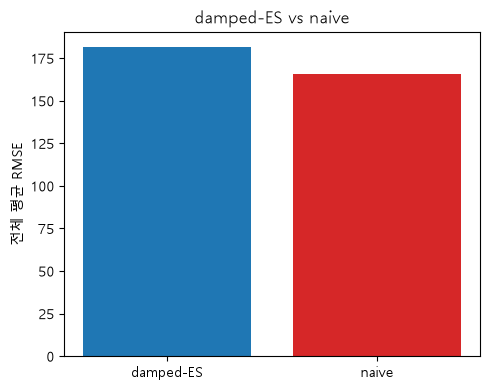

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(overall_cmp.index, overall_cmp.values, color=["#1f77b4", "#d62728"])
ax.set_ylabel("전체 평균 RMSE")
ax.set_title("damped-ES vs naive")
fig.tight_layout()
plt.show()


**해석**: 전체 평균 RMSE — damped-ES **181.5** vs naive **165.5** (naive가 더 낫다)

- 6개 변수 중 5개에서 naive가 같거나 더 좋음
- damped-ES가 이긴 건 X1 하나뿐

→ **"시계열이니까 추세모델이 최선"이라는 가정은 틀렸다.** 근사 랜덤워크 변수에 추세를
학습시키면 노이즈에 fitting될 뿐이다. 이후 시계열 대표는 damped-ES 대신 자동으로 order를
고르는 표준 방법인 **Auto-ARIMA**로 바꾸고, 여러 계열을 공정하게 비교한다.


## 1-1. 모델 정의 및 확장윈도우 백테스트

5개 모델을 `fit_forecast(values, h)` 공통 함수로 통일한다(변수별 수동 튜닝 없음). 확장윈도우로
origin을 최대한 확보해(변수당 약 33~37개) 5개 모델 × 6개 변수 × horizon(1~7)의 예측오차를 쌓는다.


In [6]:
def fc_naive(values, h=H):
    # baseline: 마지막 값을 h번 그대로 반복 (랜덤워크, 추세 없음)
    return np.repeat(values[-1], h)

def fc_auto_arima(values, h=H):
    # 시계열 대표: AIC 기준으로 (p,d,q)를 자동 탐색. 수렴 실패 시 naive로 대체
    try:
        model = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore")
        return np.asarray(model.predict(n_periods=h))
    except Exception:
        return fc_naive(values, h)

def _lag_xy(values, lag=LAG):
    # AR(lag) 학습 데이터 생성: X=과거 lag개 값, y=다음 값
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    return X, y

def _recursive_forecast(model_fit_fn, values, h=H, lag=LAG):
    # 1-step 모델 하나를 학습한 뒤, 예측값을 다음 입력으로 재사용하며 h번 반복(recursive)
    X, y = _lag_xy(values, lag)
    model = model_fit_fn(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)  # 예측값을 실제값처럼 이어붙여 다음 스텝 입력으로 사용
    return np.array(out)

def fc_ols(values, h=H):
    # 회귀 대표: 선형회귀(OLS) 기반 AR(2), recursive로 7스텝 예측
    return _recursive_forecast(lambda X, y: LinearRegression().fit(X, y), values, h)

def fc_gbm(values, h=H):
    # 트리기반 대표: GradientBoosting 기반 AR(2), recursive로 7스텝 예측
    return _recursive_forecast(
        lambda X, y: GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=0).fit(X, y),
        values, h,
    )

def fc_gp(values, h=H):
    # 커널/비모수 대표: 시간축(t/n)을 입력으로 받아 미래 h개 시점을 한 번에(joint) 예측
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1.0)  # 추세(RBF) + 관측잡음(White)
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    Xf = np.arange(n, n + h).reshape(-1, 1) / n
    mean, _ = gp.predict(Xf, return_std=True)
    return mean

MODELS = {"naive": fc_naive, "auto_arima": fc_auto_arima, "ols_lag": fc_ols, "gbm_lag": fc_gbm, "gp": fc_gp}
print("모델 5개 정의 완료:", list(MODELS.keys()))


모델 5개 정의 완료: ['naive', 'auto_arima', 'ols_lag', 'gbm_lag', 'gp']


In [7]:
t0 = time.time()
records = []
for c in COLS:
    vals = series[c]
    n = len(vals)
    # 확장윈도우: MIN_TRAIN 이후 가능한 모든 시점을 origin으로 삼아 7분기 예측을 반복
    for origin in range(MIN_TRAIN, n - H + 1):
        train, actual = vals[:origin], vals[origin:origin + H]
        for name, fn in MODELS.items():
            try:
                fc = fn(train, H)
            except Exception:
                fc = fc_naive(train, H)  # 학습/예측 실패 시 안전하게 naive로 대체
            err = actual - fc
            for h in range(1, H + 1):
                records.append({"var": c, "model": name, "origin": origin, "h": h, "err": err[h - 1]})
    print(f"{LABELS[c]} 완료 ({time.time()-t0:.0f}초 경과)")

err_df = pd.DataFrame(records)  # (변수, 모델, origin, horizon)별 예측오차 — 이후 모든 분석의 기반
print(f"총 소요시간: {time.time()-t0:.0f}초, 총 {len(err_df)}개 오차 기록")


X1 완료 (11초 경과)


X2 완료 (39초 경과)


X3 완료 (80초 경과)


X4 완료 (134초 경과)


X5 완료 (158초 경과)


X6 완료 (208초 경과)
총 소요시간: 208초, 총 7175개 오차 기록


In [8]:
# horizon 1~7 오차를 합쳐 변수 x 모델별 RMSE 산출
rmse = err_df.groupby(["var", "model"])["err"].apply(lambda e: np.sqrt(np.mean(e**2))).unstack()
rmse = rmse.rename(index=LABELS, columns=FAMILY_LABELS).round(3)
print("변수 x 모델 RMSE (7분기 평균):")
display(rmse)

# 6개 변수를 합쳐 계열별 순위를 매기기 위한 전체 평균
overall = err_df.groupby("model")["err"].apply(lambda e: np.sqrt(np.mean(e**2))).rename(index=FAMILY_LABELS)
overall = overall.sort_values().round(3).to_frame("전체 평균 RMSE")
print("전체 평균 RMSE (낮을수록 좋음):")
display(overall)


변수 x 모델 RMSE (7분기 평균):


model,시계열 (Auto-ARIMA),트리기반 (GBM),커널/비모수 (GP),baseline (naive),회귀 (선형회귀)
var,,,,,
X1,181.381,211.149,182.494,262.870,185.796
X2,0.007,0.010,0.008,0.010,0.008
X3,332.868,323.848,301.172,313.334,316.292
X4,0.038,0.047,0.037,0.045,0.036
X5,0.069,0.078,0.060,0.077,0.067
X6,0.012,0.012,0.015,0.011,0.013


전체 평균 RMSE (낮을수록 좋음):


,전체 평균 RMSE
model,
커널/비모수 (GP),142.846
회귀 (선형회귀),148.826
시계열 (Auto-ARIMA),153.859
트리기반 (GBM),156.752
baseline (naive),165.550


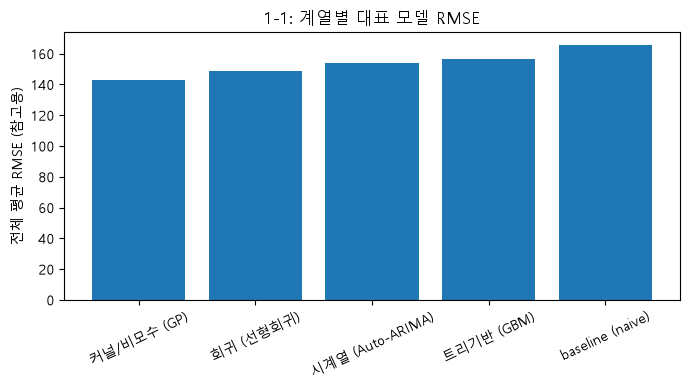

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(overall["전체 평균 RMSE"].index, overall["전체 평균 RMSE"].values, color="#1f77b4")
ax.set_ylabel("전체 평균 RMSE (참고용)")
ax.set_title("1-1: 계열별 대표 모델 RMSE")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()


**해석**: 변수마다 잘 맞는 계열이 다르다 — 노이즈 큰 X1는 GP/회귀가 강세, 안정적인
변수는 naive도 밀리지 않는다. "변수마다 다른 모델 안 쓴다"는 조건상, **전체 평균이 낮고
일관된 계열**을 우선한다.


## 1-2. 예측구간 90% 커버리지 확인

각 모델 오차로 90% joint 구간(7분기 경로 전체가 동시에 담길 확률 90%)을
out-of-sample로 확인한다. k를 추정한 데이터로 그 k의 커버리지를 재면 순환계산이라,
origin을 앞 70%(calibration)/뒤 30%(test)로 나눈다: calibration에서 horizon별
sigma_h·배율 k 산출 → test에 적용.

**sigma_h를 h마다 따로 계산하는 이유**: 구간폭=k×sigma_h(h)라, sigma_h가 h에 따라
커지면 구간도 자동으로 팬차트 모양이 된다 (예: Auto-ARIMA·X3의 sigma_h가
h=1: 111.7 → h=7: 358.3, 3배 이상).


In [10]:
CALIB_FRAC = 0.7  # origin의 앞 70%는 k 추정(calibration), 뒤 30%는 out-of-sample 검증(test)

calib_parts, test_parts = [], []
for (v, m), g in err_df.groupby(["var", "model"]):
    origins = sorted(g["origin"].unique())
    n_calib = int(np.ceil(len(origins) * CALIB_FRAC))
    calib_set = set(origins[:n_calib])  # 시간순 앞쪽만 calibration으로 (미래 정보 누출 방지)
    calib_parts.append(g[g["origin"].isin(calib_set)])
    test_parts.append(g[~g["origin"].isin(calib_set)])
calib_err = pd.concat(calib_parts)
test_err = pd.concat(test_parts)

# calibration 데이터로만 horizon별 오차 표준편차 산출 (test는 전혀 안 봄)
sigma_calib = calib_err.groupby(["var", "model", "h"])["err"].std().reset_index(name="sigma_h")

def add_z(df):
    # 오차를 sigma_h로 표준화 (변수마다 스케일이 달라서 표준화해야 모델·변수 간 비교가 가능)
    out = df.merge(sigma_calib, on=["var", "model", "h"])
    out["z"] = out["err"] / out["sigma_h"]
    return out

# 각 origin에서 "7개 horizon 중 가장 크게 벗어난" 표준화오차 — joint 커버리지 판단 기준
calib_max = add_z(calib_err).groupby(["model", "var", "origin"])["z"].apply(lambda z: z.abs().max()).reset_index(name="max_abs_z")
test_max = add_z(test_err).groupby(["model", "var", "origin"])["z"].apply(lambda z: z.abs().max()).reset_index(name="max_abs_z")

# calibration의 90번째 백분위수를 구간 배율 k로 사용 (6개 변수 풀링)
k_by_model = calib_max.groupby("model")["max_abs_z"].quantile(0.90)

rows = []
var_std = {c: series[c].std() for c in COLS}
for name in MODELS:
    k = k_by_model[name]
    test_sub = test_max[test_max["model"] == name]
    coverage = (test_sub["max_abs_z"] <= k).mean()  # k를 한 번도 못 본 test에서 실제 커버리지 확인
    sig_sub = sigma_calib[sigma_calib["model"] == name]
    rel_width = (2 * k * sig_sub["sigma_h"]) / sig_sub["var"].map(var_std)  # 구간폭을 변수 표준편차로 정규화(비교 가능하게)
    rows.append({
        "모델": FAMILY_LABELS[name],
        "k(calibration)": round(k, 3),
        "test 커버리지(out-of-sample)": f"{coverage:.1%}",
        "평균 상대폭(구간폭/변수표준편차)": round(rel_width.mean(), 2),
    })

coverage_df = pd.DataFrame(rows).set_index("모델")
n_test = len(test_max) // len(MODELS)
print(f"calibration:test = {CALIB_FRAC:.0%}:{1-CALIB_FRAC:.0%}, 모델당 test 표본 {n_test}개(6개 변수 풀링)")
display(coverage_df)


calibration:test = 70%:30%, 모델당 test 표본 59개(6개 변수 풀링)


,k(calibration),test 커버리지(out-of-sample),평균 상대폭(구간폭/변수표준편차)
모델,,,
baseline (naive),2.300,74.6%,5.34
시계열 (Auto-ARIMA),2.214,67.8%,4.33
회귀 (선형회귀),2.247,69.5%,4.30
트리기반 (GBM),2.306,72.9%,5.05
커널/비모수 (GP),2.375,71.2%,4.45


**한계**: test 표본이 모델당 약 60개뿐이라 추정 표준오차가 ±4%p 안팎이다. 그래도 이전
순환계산과 달리, 모델이 나쁘면 실제로 90%를 벗어날 수 있는 **진짜 검증**이다.


## 1-2 보충. Leave-one-out으로 재검증

70:30은 test가 59개뿐이라 불안정하다. **LOO**로 바꾸면 거의 전체 데이터(약 205개)를
calibration·test 양쪽에 다 쓸 수 있다:

- (변수, origin) 하나씩 빼고, **나머지 전부**로 sigma_h·k 재계산 후 그 점이 커버됐는지 확인
- 205개 점 전부 반복 — 순환계산은 아니지만(자신은 계산에서 제외됨), 70:30보다 표본을
  훨씬 많이 씀


In [11]:
def loo_coverage_for(name):
    # (변수, origin) 하나를 남기고, 같은 변수의 나머지 origin으로 sigma_h를 계산해
    # 그 하나의 표준화오차(자신은 계산에서 제외)를 구한다
    e = err_df[err_df["model"] == name]
    max_abs_list = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for o in origins:
            train_g = g[g["origin"] != o]
            sigma_loo = train_g.groupby("h")["err"].std()
            test_row = g[g["origin"] == o].set_index("h")["err"]
            z = test_row / sigma_loo
            max_abs_list.append(z.abs().max())
    return np.array(max_abs_list)

loo_rows = []
loo_arrays = {}
for name in MODELS:
    arr = loo_coverage_for(name)
    loo_arrays[name] = arr
    n = len(arr)
    # 각 점을 자기 자신은 뺀 나머지 204개로 구한 k와 비교 (순환계산 아님)
    covered = np.array([arr[i] <= np.quantile(np.delete(arr, i), 0.90) for i in range(n)])
    loo_rows.append({
        "모델": FAMILY_LABELS[name],
        "LOO 커버리지": f"{covered.mean():.1%}",
        "표본 수": n,
    })

loo_df = pd.DataFrame(loo_rows).set_index("모델")
compare_df = coverage_df[["test 커버리지(out-of-sample)"]].join(loo_df)
compare_df = compare_df.rename(columns={"test 커버리지(out-of-sample)": "70:30 split 커버리지"})
display(compare_df)


,70:30 split 커버리지,LOO 커버리지,표본 수
모델,,,
baseline (naive),74.6%,89.8%,205
시계열 (Auto-ARIMA),67.8%,89.8%,205
회귀 (선형회귀),69.5%,89.3%,205
트리기반 (GBM),72.9%,89.3%,205
커널/비모수 (GP),71.2%,89.8%,205


**비교 해석**: LOO가 70:30보다 훨씬 높게(90% 근처) 나온 이유는 표본이 많아서가 아니라
**미래 정보 누출** 때문이다.

- 특정 origin을 검증할 때 더 나중 시점의 origin까지 calibration에 섞인다(실제 서비스에선 불가능)
- Conformal 이론상 calibration=test가 교환가능하면 커버리지가 목표치 근처로 나오도록
  설계돼 있어서, 이 누출과 맞물려 모델 성능과 무관하게 다들 90% 근처로 몰렸다

→ **미래 정보 없이 표본을 많이 쓰는 방법**이 필요하다.


## 1-2 최종. 확장윈도우(walk-forward) 방식

70:30(표본 부족)과 LOO(미래정보 누출) 둘 다 피하는 방법. origin을 시간순 정렬해 초기
15개까진 calibration 전용으로, 그 다음부터는 **그 시점 이전 origin만으로** sigma_h·k를
계산해 한 시점씩 검증하며 앞으로 나아간다.

→ 미래 정보 없이, 여러 시기에 걸쳐, 거의 모든 origin(변수당 약 18~22개, 총 약 120개)을
검증에 쓸 수 있다.


In [12]:
INITIAL_CALIB = 15  # 이 개수만큼은 순수 calibration 전용으로 쌓아두고 시작

def walkforward_coverage_for(name, quantile=0.90, safety=1.0):
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib_origins = origins[:i]   # 검증 시점보다 앞선 origin만 사용 (미래 정보 누출 없음)
            test_origin = origins[i]
            calib_errs = g[g["origin"].isin(calib_origins)]
            sigma_h = calib_errs.groupby("h")["err"].std()

            calib_pivot = calib_errs.pivot(index="origin", columns="h", values="err")
            calib_z = calib_pivot.div(sigma_h, axis=1)
            k = calib_z.abs().max(axis=1).quantile(quantile) * safety  # safety: 1-3에서 튜닝용으로 사용

            test_errs = g[g["origin"] == test_origin].set_index("h")["err"]
            test_max_z = (test_errs / sigma_h).abs().max()

            rows.append({
                "var": v, "origin": test_origin, "k": k,
                "sigma_h_mean": sigma_h.mean(), "covered": test_max_z <= k,
            })
    return pd.DataFrame(rows)

wf_rows = []
wf_results = {}
var_std = {c: series[c].std() for c in COLS}
for name in MODELS:
    wf = walkforward_coverage_for(name)
    wf_results[name] = wf
    rel_width = (2 * wf["k"] * wf["sigma_h_mean"]) / wf["var"].map(var_std)
    wf_rows.append({
        "모델": FAMILY_LABELS[name],
        "walk-forward 커버리지": f"{wf['covered'].mean():.1%}",
        "표본 수": len(wf),
        "평균 상대폭": round(rel_width.mean(), 2),
    })

wf_df = pd.DataFrame(wf_rows).set_index("모델")
display(wf_df)

,walk-forward 커버리지,표본 수,평균 상대폭
모델,,,
baseline (naive),59.1%,115,4.78
시계열 (Auto-ARIMA),60.0%,115,4.24
회귀 (선형회귀),65.2%,115,4.15
트리기반 (GBM),65.2%,115,4.85
커널/비모수 (GP),61.7%,115,4.11


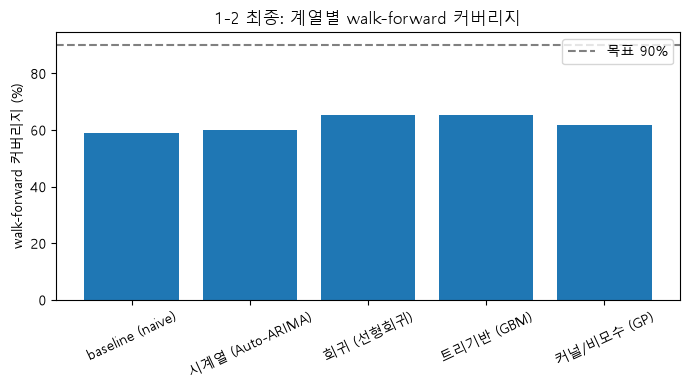

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(wf_df["walk-forward 커버리지"].str.rstrip("%").astype(float).index,
       wf_df["walk-forward 커버리지"].str.rstrip("%").astype(float).values, color="#1f77b4")
ax.axhline(90, color="gray", linestyle="--", label="목표 90%")
ax.set_ylabel("walk-forward 커버리지 (%)")
ax.set_title("1-2 최종: 계열별 walk-forward 커버리지")
ax.tick_params(axis="x", rotation=25)
ax.legend()
fig.tight_layout()
plt.show()


**해석**: walk-forward 커버리지(**59~65%**)가 70:30(67.8~74.6%)보다 더 낮다.

- 방법이 잘못된 게 아니라, 미래 누출도 특정 시기 편중도 없이 재보니 미달 정도가 더 크게
  드러난 것이다
- 세 방법(70:30·LOO·walk-forward) 결론은 같다: **지금 k 산출 방식(calibration 90번째
  백분위수)으로는 90% 목표를 못 채운다**

이건 모델 선정과 별개 문제이며, 모델을 고른 뒤 k 보정으로 따로 푼다. 1-3 선정에는
walk-forward 결과를 쓴다.


## 1-3. 모델 종류 선정

raw(안 튜닝된) 커버리지 근접도 + raw 구간폭으로 순위를 매기는 건 틀렸다 — 우연히 잘
맞은 것과 실제로 좋은 모델은 다르다.

**기준**: 5개 모델 각각을 90% 커버리지에 맞게 튜닝한 뒤, **그때의 구간폭**만 비교한다.


In [14]:
def tune_safety(name, target=0.90, grid=np.arange(1.0, 3.01, 0.02)):
    # walk-forward 커버리지가 target(90%)에 가장 가까워지는 safety 배율을 탐색
    best = None
    for s in grid:
        wf = walkforward_coverage_for(name, quantile=0.90, safety=s)
        cov = wf["covered"].mean()
        rel_width = (2 * wf["k"] * wf["sigma_h_mean"]) / wf["var"].map(var_std)
        gap = abs(cov - target)
        if best is None or gap < best["gap"]:
            best = {"safety": round(s, 2), "커버리지(%)": round(cov * 100, 1),
                    "평균 상대폭": round(rel_width.mean(), 2), "gap": gap}
    return best

tune_rows = []
for name in MODELS:
    best = tune_safety(name)
    tune_rows.append({"모델": FAMILY_LABELS[name], **best})

tune_df = pd.DataFrame(tune_rows).set_index("모델").drop(columns="gap")
tune_df = tune_df.sort_values("평균 상대폭")  # 커버리지가 다들 ~90%로 맞춰졌으니 구간폭만으로 순위
display(tune_df)

winner = tune_df.index[0]
print(f"선정된 모델 계열: {winner}")


,safety,커버리지(%),평균 상대폭
모델,,,
시계열 (Auto-ARIMA),1.56,89.6,6.61
커널/비모수 (GP),1.66,89.6,6.83
baseline (naive),1.44,89.6,6.88
회귀 (선형회귀),1.66,89.6,6.89
트리기반 (GBM),1.56,89.6,7.57


선정된 모델 계열: 시계열 (Auto-ARIMA)


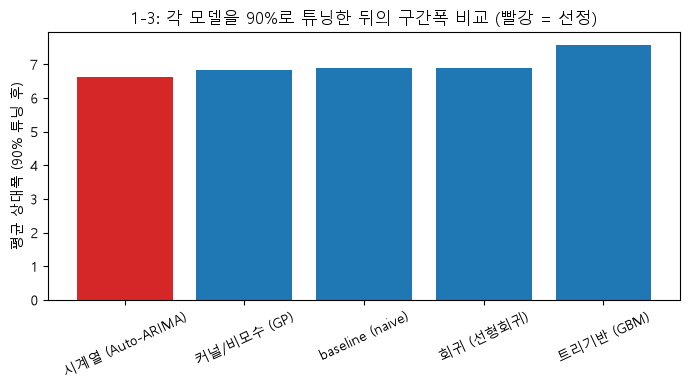

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#d62728" if n == winner else "#1f77b4" for n in tune_df.index]
ax.bar(tune_df.index, tune_df["평균 상대폭"], color=colors)
ax.set_ylabel("평균 상대폭 (90% 튜닝 후)")
ax.set_title("1-3: 각 모델을 90%로 튜닝한 뒤의 구간폭 비교 (빨강 = 선정)")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()


**해석**: 90%로 개별 튜닝하니 순위가 완전히 바뀌었다.

- Auto-ARIMA: 구간폭 **6.61**로 1위 (raw 비교에선 하위권)
- GP 6.83, naive 6.88, 회귀 6.89 — 2~4위는 근소한 차이
- GBM 7.57 — 확실한 최하위

→ **Auto-ARIMA를 선정한다.**


### 부수 검증: 이 순위가 노이즈는 아닌가

1~4위 구간폭 차이(6.61~6.89)가 크지 않아서, origin을 복원추출(bootstrap)해도 순위가
유지되는지 확인한다. 먼저 기존 방식(safety는 고정하고 origin만 재추출)으로 해본다.


In [16]:
def rel_width_table(name, safety):
    wf = walkforward_coverage_for(name, quantile=0.90, safety=safety)
    wf["rel_width"] = (2 * wf["k"] * wf["sigma_h_mean"]) / wf["var"].map(var_std)
    return wf

# 1-3에서 이미 구한 모델별 최적 safety를 그대로 재사용 (튜닝 자체는 재탐색하지 않음)
optimal_safety = {name: tune_df.loc[FAMILY_LABELS[name], "safety"] for name in MODELS}
per_model = {name: rel_width_table(name, optimal_safety[name]) for name in MODELS}

rng = np.random.default_rng(0)
N_BOOT = 2000
var_origins = {v: sorted(per_model["naive"][per_model["naive"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {name: 0 for name in MODELS}
rank_sum = {name: 0.0 for name in MODELS}
for _ in range(N_BOOT):
    # 변수별로 origin을 복원추출 (safety는 고정, origin만 재추출)
    resample_idx = {v: rng.choice(var_origins[v], size=len(var_origins[v]), replace=True) for v in COLS}
    means = {}
    for name in MODELS:
        m = per_model[name]
        vals = []
        for v in COLS:
            sub = m[m["var"] == v].set_index("origin")
            vals.extend(sub.loc[resample_idx[v], "rel_width"].values)
        means[name] = np.mean(vals)
    order = sorted(MODELS, key=lambda n: means[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

boot_df_simple = pd.DataFrame([
    {"모델": FAMILY_LABELS[n], "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1), "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in MODELS
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(boot_df_simple)


,1위 비율(%),평균 순위
모델,,
시계열 (Auto-ARIMA),100.0,1.00
baseline (naive),0.0,3.29
회귀 (선형회귀),0.0,3.54
트리기반 (GBM),0.0,5.00
커널/비모수 (GP),0.0,2.17


**해석**: 단순 부트스트랩(safety 고정, origin만 재추출, 2000회)에서는 **Auto-ARIMA가
전부 1위**(100%)를 차지한다. 그런데 이 방식은 "목표 커버리지에 맞춰 튜닝하는 과정
자체"가 이 데이터에 과적합됐는지는 검증하지 못한다 — safety를 매번 다시 찾도록(중첩)
바꾸면 결과가 달라지는지 아래에서 확인한다.


### 부수 검증 (개선): 중첩+블록 부트스트랩

위 단순 부트스트랩은 "목표 커버리지에 맞춰 튜닝하는 과정 자체"가 이 데이터에
과적합됐는지는 전혀 검증하지 못한다. 이를 보완해 두 가지를 바꾼 부트스트랩을 다시 돈다:

- **중첩(nested)**: 재추출할 때마다 safety를 처음부터 다시 탐색한다(고정하지 않음).
- **블록(block)**: origin을 하나씩이 아니라 4개씩 묶어서 재추출한다 — 확장윈도우 구조상
  인접 origin끼리는 서로 독립이 아니기 때문이다.


In [17]:
def precompute_for_boot(name):
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib_errs = g[g["origin"].isin(origins[:i])]
            sigma_h = calib_errs.groupby("h")["err"].std()
            calib_pivot = calib_errs.pivot(index="origin", columns="h", values="err")
            k_base = calib_pivot.div(sigma_h, axis=1).abs().max(axis=1).quantile(0.90)
            test_errs = g[g["origin"] == origins[i]].set_index("h")["err"]
            test_max_z = (test_errs / sigma_h).abs().max()
            rows.append({"var": v, "origin": origins[i], "k_base": k_base,
                         "sigma_h_mean": sigma_h.mean(), "test_max_z": test_max_z})
    return pd.DataFrame(rows)

pre_boot = {name: precompute_for_boot(name) for name in MODELS}

def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]

rng = np.random.default_rng(0)
N_BOOT, BLOCK_LEN = 500, 4
grid = np.arange(1.0, 3.001, 0.02)
var_origin_lists = {v: sorted(pre_boot["naive"][pre_boot["naive"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {n: 0 for n in MODELS}
rank_sum = {n: 0.0 for n in MODELS}
for _ in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng) for v in COLS}
    widths = {}
    for name in MODELS:
        df = pre_boot[name]
        sub = pd.concat(df[df["var"] == v].set_index("origin").loc[resampled[v]] for v in COLS)
        best_width, best_gap = None, np.inf
        for s in grid:
            cov = (sub["test_max_z"] <= sub["k_base"] * s).mean()
            gap = abs(cov - 0.90)
            if gap < best_gap:
                best_gap = gap
                best_width = (2 * sub["k_base"] * s * sub["sigma_h_mean"] / sub["var"].map(var_std)).mean()
        widths[name] = best_width
    order = sorted(MODELS, key=lambda n: widths[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

boot_df = pd.DataFrame([
    {"모델": FAMILY_LABELS[n], "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1), "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in MODELS
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(boot_df)


,1위 비율(%),평균 순위
모델,,
시계열 (Auto-ARIMA),80.8,1.27
회귀 (선형회귀),14.6,2.34
커널/비모수 (GP),3.2,3.15
트리기반 (GBM),1.2,4.64
baseline (naive),0.2,3.60


**해석**: Auto-ARIMA 1위 비율 **80.8%**(평균 순위 1.27)로 여전히 우세하지만, 기존
"100%"보다 낮아졌다 — 회귀가 14.6%로 가끔 뒤집힌다. **결론(Auto-ARIMA)은 그대로지만,
이전 단순 부트스트랩의 "100% 확신"은 과장이었다.**


### 1-3 최종: 선정 기준을 Winkler(interval) score로 교체

90% 튜닝 방식은 (1) 탐색 과정 자체가 과적합될 수 있고(부트스트랩 100%→80.8%),
(2) 모델마다 도달 커버리지가 달라 불공정 비교가 될 수 있다. 목표(90%)는 유지하되
**Winkler score**(α=0.10)로 기준을 바꾼다 — 튜닝 없이 커버리지 실패+구간폭을
하나로 평가.

`score = (u-l) + (2/α)(l-y)·1{y<l} + (2/α)(y-u)·1{y>u}`

**참고**: k(구간폭을 정하는 90분위수, calibration에서 한 번 계산)와 α(벌점 강도)는
다른 역할이다 — 버린 건 "hold-out 성능 보고 반복 탐색"이지 "90%를 쓴다는 것"
자체가 아니다. α는 "1-목표 커버리지"로 정의상 정해지는 값(80%→0.20, 95%→0.05)일
뿐 별도 튜닝 대상이 아니다.


In [18]:
ALPHA = 0.10  # 90% 단일 수준

def winkler_score(name, alpha):
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib_errs = g[g["origin"].isin(origins[:i])]
            sigma_h = calib_errs.groupby("h")["err"].std()
            calib_pivot = calib_errs.pivot(index="origin", columns="h", values="err")
            k = calib_pivot.div(sigma_h, axis=1).abs().max(axis=1).quantile(0.90)  # raw k (safety=1)
            test_errs = g[g["origin"] == origins[i]].set_index("h")["err"]
            lo, hi = -k * sigma_h, k * sigma_h
            width = hi - lo
            below, above = test_errs < lo, test_errs > hi
            score = width.copy()
            score[below] = width[below] + (2 / alpha) * (lo[below] - test_errs[below])
            score[above] = width[above] + (2 / alpha) * (test_errs[above] - hi[above])
            scores.append(score.mean() / var_std[v])
    return np.mean(scores)

rows = []
for name in MODELS:
    w90 = winkler_score(name, ALPHA)
    rows.append({"모델": FAMILY_LABELS[name], "Winkler@90%": round(w90, 3)})
winkler_combined = pd.DataFrame(rows).set_index("모델").sort_values("Winkler@90%")
display(winkler_combined)
print(f"선정된 모델 계열: {winkler_combined.index[0]}")


,Winkler@90%
모델,
시계열 (Auto-ARIMA),5.248
회귀 (선형회귀),5.303
커널/비모수 (GP),5.336
트리기반 (GBM),6.007
baseline (naive),6.029


선정된 모델 계열: 시계열 (Auto-ARIMA)


**해석**: Winkler(90%) 기준으로 **Auto-ARIMA가 1위**다(5.248, 회귀 5.303, GP 5.336) —
이 결과를 최종 선정 기준으로 채택한다: **Auto-ARIMA**.


**참고**: Winkler는 튜닝(safety 탐색) 과적합 문제는 없앴지만, origin 표본이 변수당
33~37개뿐이라 어떤 지표를 쓰든 순위 자체가 노이즈일 수 있다는 문제는 그대로 남는다.
다만 탐색 단계가 없어 "중첩"할 대상이 없으므로, origin만 블록(4개씩) 재추출하는
block bootstrap(500회)만으로 충분하다.


In [19]:
def precompute_winkler_components(name):
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib_errs = g[g["origin"].isin(origins[:i])]
            sigma_h = calib_errs.groupby("h")["err"].std()
            calib_pivot = calib_errs.pivot(index="origin", columns="h", values="err")
            k = calib_pivot.div(sigma_h, axis=1).abs().max(axis=1).quantile(0.90)
            test_errs = g[g["origin"] == origins[i]].set_index("h")["err"]
            lo, hi = -k * sigma_h, k * sigma_h
            width = hi - lo
            breach = pd.Series(0.0, index=width.index)
            below, above = test_errs < lo, test_errs > hi
            breach[below] = lo[below] - test_errs[below]
            breach[above] = test_errs[above] - hi[above]
            rows.append({"var": v, "origin": origins[i],
                         "width_mean": width.mean() / var_std[v], "breach_mean": breach.mean() / var_std[v]})
    return pd.DataFrame(rows)

pre_wink = {name: precompute_winkler_components(name) for name in MODELS}

def combined_score(df):
    return (df["width_mean"] + (2 / ALPHA) * df["breach_mean"]).mean()

rng = np.random.default_rng(0)
N_BOOT, BLOCK_LEN = 500, 4
var_origin_lists = {v: sorted(pre_wink["naive"][pre_wink["naive"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {n: 0 for n in MODELS}
rank_sum = {n: 0.0 for n in MODELS}
for _ in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng) for v in COLS}
    scores = {}
    for name in MODELS:
        df = pre_wink[name]
        sub = pd.concat(df[df["var"] == v].set_index("origin").loc[resampled[v]] for v in COLS)
        scores[name] = combined_score(sub)
    order = sorted(MODELS, key=lambda n: scores[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

winkler_boot_df = pd.DataFrame([
    {"모델": FAMILY_LABELS[n], "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1), "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in MODELS
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(winkler_boot_df)


,1위 비율(%),평균 순위
모델,,
시계열 (Auto-ARIMA),75.8,1.35
회귀 (선형회귀),16.8,1.89
커널/비모수 (GP),7.4,2.77
baseline (naive),0.0,4.68
트리기반 (GBM),0.0,4.31


**해석**: Auto-ARIMA 1위 비율 **75.8%** — 90% 폭 비교 기준 부트스트랩(80.8%)과
비슷한 수준으로, 두 기준이 같은 결론에 수렴한다.

**참고**: Winkler도 구간을 대칭 가산 방식(`점예측 ± k×sigma_h`)으로 만들기 때문에,
X3처럼 하한이 있는 변수의 음수 문제(1-4 참고)는 해결하지 못한다 — 커버리지
목표나 선정 기준과 무관한 별도 한계다.


## 1-4. 90% 구간이 실용적인가

1-3에서 선정된 Auto-ARIMA로 실제 7분기 예측 구간을 그려보고, 이 구간이 실용적인지 확인한다.


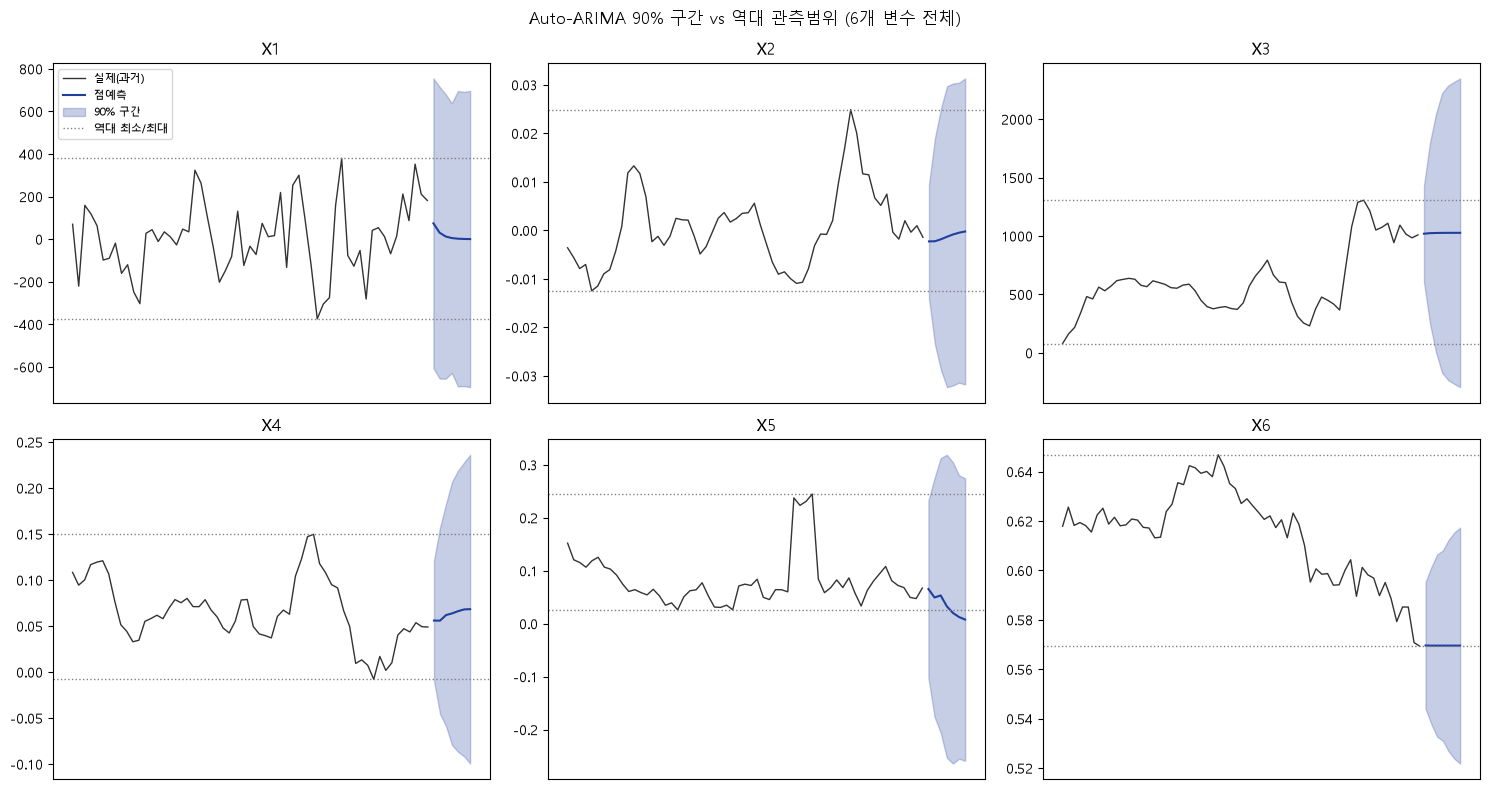

In [20]:
sigma_h_all = err_df[err_df["model"] == "auto_arima"].groupby(["var", "h"])["err"].std().unstack()
merged = err_df[err_df["model"] == "auto_arima"].merge(
    sigma_h_all.stack().rename("sigma_h").reset_index(), on=["var", "h"]
)
merged["z"] = merged["err"] / merged["sigma_h"]
max_abs = merged.groupby(["var", "origin"])["z"].apply(lambda z: z.abs().max())
k_base_arima = max_abs.quantile(0.90)
k_final_arima = k_base_arima * 1.56  # 1-3에서 찾은 Auto-ARIMA의 safety

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, COLS):
    hist = series[c]
    fc = fc_auto_arima(hist)
    band = k_final_arima * sigma_h_all.loc[c].values
    x_hist, x_fut = range(len(hist)), range(len(hist), len(hist) + H)
    ax.plot(x_hist, hist, color="#333", lw=1, label="실제(과거)")
    ax.plot(x_fut, fc, color="#1f3f9e", lw=1.5, label="점예측")
    ax.fill_between(x_fut, fc - band, fc + band, color="#1f3f9e", alpha=0.25, label="90% 구간")
    ax.axhline(hist.min(), color="gray", ls=":", lw=1, label="역대 최소/최대")
    ax.axhline(hist.max(), color="gray", ls=":", lw=1)
    ax.set_title(LABELS[c])
    ax.set_xticks([])
axes.flat[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Auto-ARIMA 90% 구간 vs 역대 관측범위 (6개 변수 전체)")
fig.tight_layout()
plt.show()


**해석**: X3(X3, 음수 불가능한 물리량)의 90% 구간
하한이 **-295**까지 내려간다 — 구조적으로 나올 수 없는 값이다. 나머지 5개 변수도 역대
범위를 벗어나지만 물리적 제약이 없어 약한 정황 증거 정도다. 대안으로 80%+95% 이중 밴드도
고려할 만하다(1-5 참고).


## 1-5. 참고: 80%+95% 이중 밴드라는 대안

R의 `forecast` 패키지 등에서 쓰는 방식처럼, 90% 하나 대신 **80%(안쪽, 평소 범위) +
95%(바깥쪽, 최악의 경우)**로 나눌 수도 있다. 80%→90%는 폭이 25% 넓어지는데 90%→95%는
7%만 넓어져서, 90%는 다소 애매한 지점이라는 게 참고할 만한 근거다. **이번 프로젝트의
목표는 90%이므로 정식 채택하지는 않고, 참고용 대안으로만 남긴다.**


(Winkler score 계산은 1-3 최종 섹션에서 다뤘다. 여기서는 80%+95% 밴드 자체를
시각적으로 비교한다.)


### 참고: 90% 단일 구간 vs 80%+95% 이중 구간

Auto-ARIMA 기준으로 둘을 나란히 그려 비교한다.


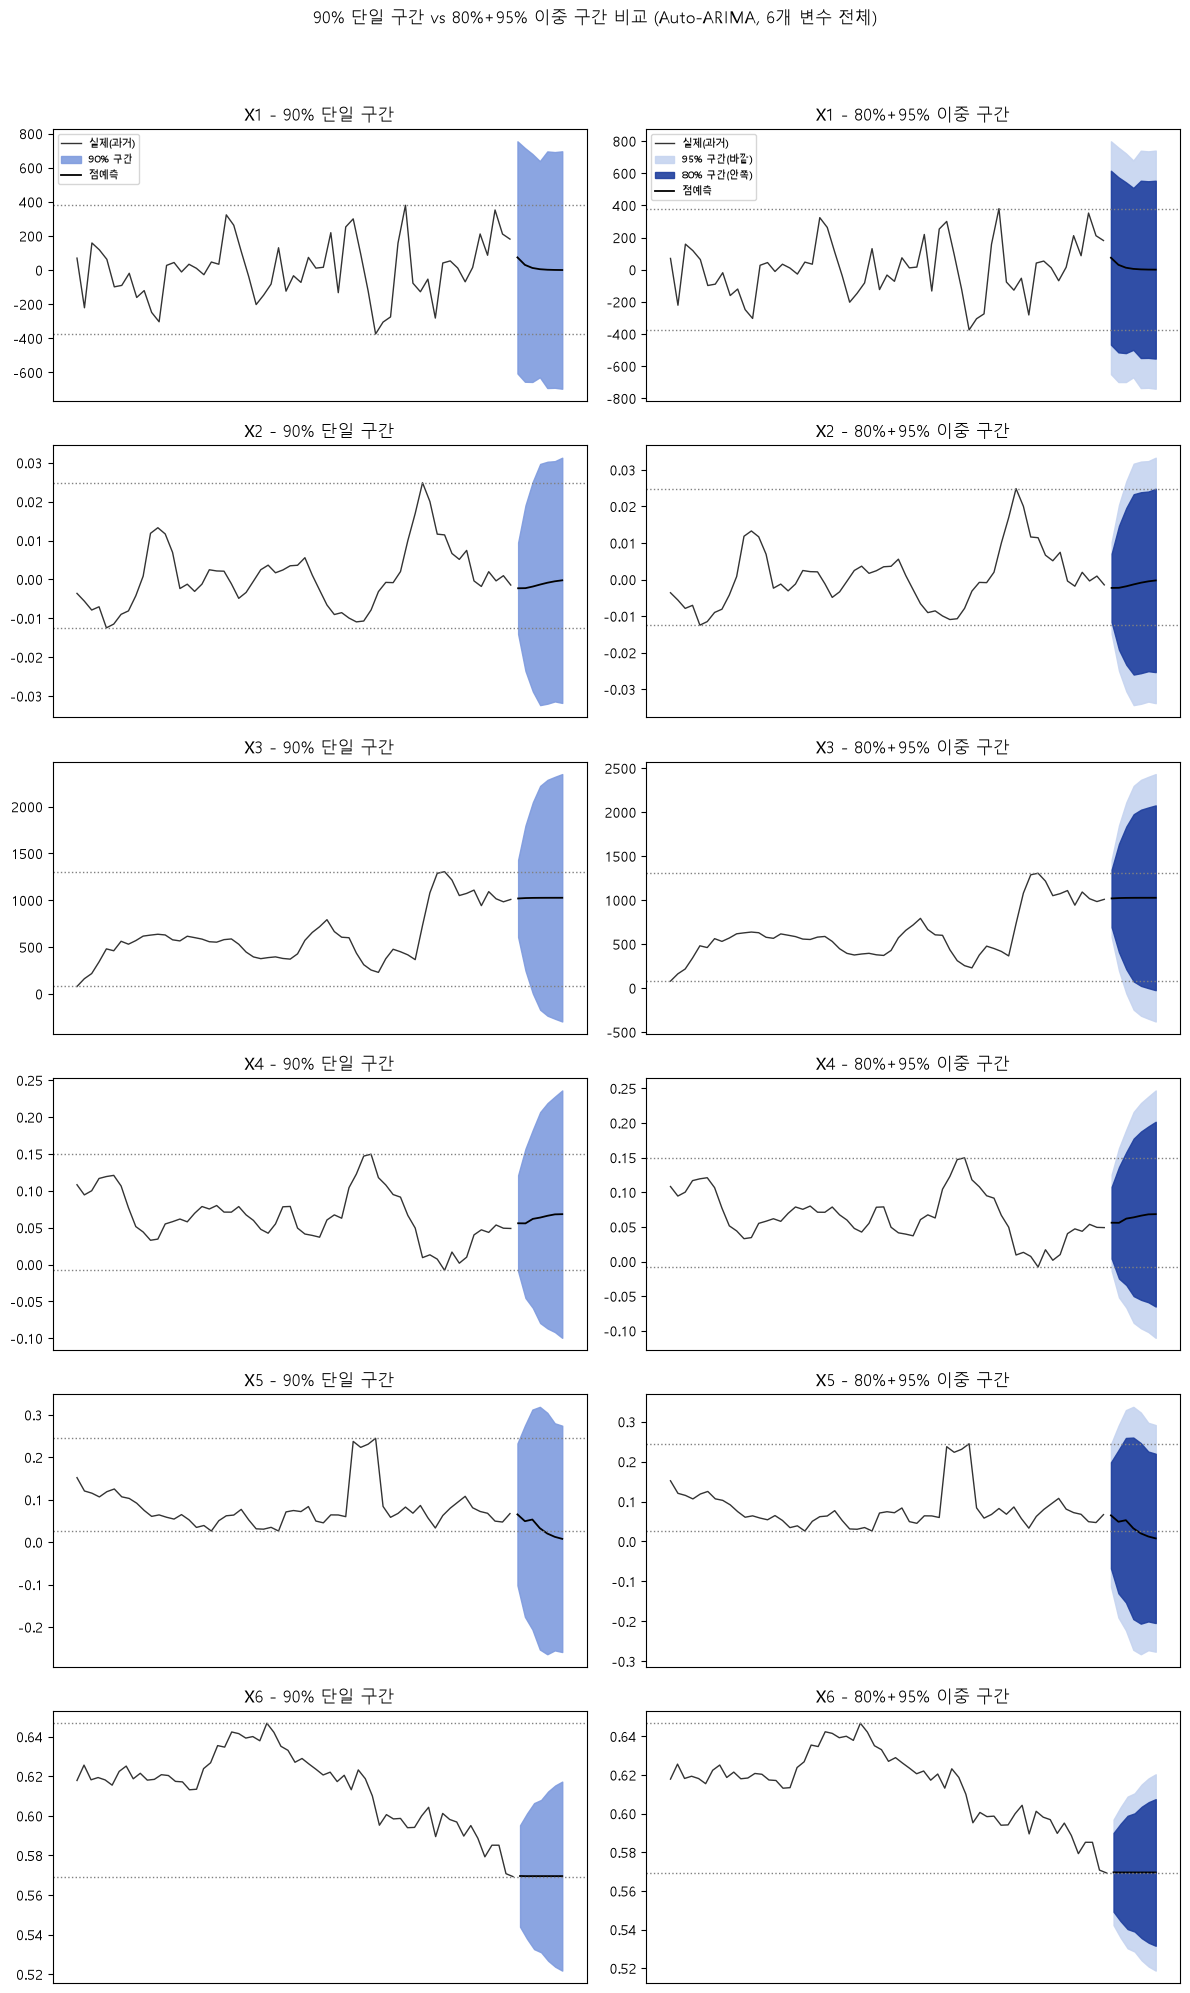

safety  80%=1.24  90%=1.56  95%=1.66


In [21]:
safety_80 = tune_safety("auto_arima", target=0.80)["safety"]
safety_90 = tune_df.loc[FAMILY_LABELS["auto_arima"], "safety"]
safety_95 = tune_safety("auto_arima", target=0.95)["safety"]
SAFETY = {"80%": safety_80, "90%": safety_90, "95%": safety_95}

fig, axes = plt.subplots(6, 2, figsize=(12, 20))
for row, c in enumerate(COLS):
    hist = series[c]
    fc = fc_auto_arima(hist)
    x_hist, x_fut = range(len(hist)), range(len(hist), len(hist) + H)

    ax = axes[row, 0]
    band90 = k_base_arima * SAFETY["90%"] * sigma_h_all.loc[c].values
    ax.plot(x_hist, hist, color="#333", lw=1, label="실제(과거)")
    ax.fill_between(x_fut, fc - band90, fc + band90, color="#7f9bde", alpha=0.9, label="90% 구간")
    ax.plot(x_fut, fc, color="#000", lw=1.3, label="점예측")
    ax.axhline(hist.min(), color="gray", ls=":", lw=1)
    ax.axhline(hist.max(), color="gray", ls=":", lw=1)
    ax.set_title(f"{LABELS[c]} - 90% 단일 구간")
    ax.set_xticks([])
    if row == 0:
        ax.legend(loc="upper left", fontsize=7)

    ax = axes[row, 1]
    band80 = k_base_arima * SAFETY["80%"] * sigma_h_all.loc[c].values
    band95 = k_base_arima * SAFETY["95%"] * sigma_h_all.loc[c].values
    ax.plot(x_hist, hist, color="#333", lw=1, label="실제(과거)")
    ax.fill_between(x_fut, fc - band95, fc + band95, color="#c6d4f0", alpha=0.9, label="95% 구간(바깥)")
    ax.fill_between(x_fut, fc - band80, fc + band80, color="#1f3f9e", alpha=0.9, label="80% 구간(안쪽)")
    ax.plot(x_fut, fc, color="#000", lw=1.3, label="점예측")
    ax.axhline(hist.min(), color="gray", ls=":", lw=1)
    ax.axhline(hist.max(), color="gray", ls=":", lw=1)
    ax.set_title(f"{LABELS[c]} - 80%+95% 이중 구간")
    ax.set_xticks([])
    if row == 0:
        ax.legend(loc="upper left", fontsize=7)

fig.suptitle("90% 단일 구간 vs 80%+95% 이중 구간 비교 (Auto-ARIMA, 6개 변수 전체)", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

print(f"safety  80%={safety_80:.2f}  90%={safety_90:.2f}  95%={safety_95:.2f}")


**해석**: 80%+95%의 바깥쪽 경계(95%)가 90% 구간과 비슷한 위치라, 폭을 크게 늘리지
않고도 안쪽에 80%(평소 범위) 정보가 추가된다. 정식 채택 기준은 아니지만 참고용 대안으로
남겨둔다.


## 결론

- **선정 모델: Auto-ARIMA**
- 1차: raw 비교(결함) → 90% 튜닝 후 폭 비교로 교정 — Auto-ARIMA 1위(폭 6.61),
  중첩+블록 부트스트랩 80.8%로 확인.
- 90% 튜닝 방식(튜닝 과적합, 불공정 비교 위험) 문제로 **최종 기준을 Winkler
  score(90%, 튜닝 불필요)로 교체** — 동일하게 Auto-ARIMA 1위(5.25), block
  bootstrap 75.8%.
- **참고(대안 밴드)**: 90% 구간이 X3에서 하한 -295까지 내려가는 등
  구조적으로 불가능한 값을 냄 — 80+95% 이중 밴드도 대안.
- **한계**: origin 33~37개로 적음, 대칭 가산 구간이 물리적 제약(음수 불가 등)을
  반영 못함.
- **다음 단계**: Winkler(90%) 기준으로 4번 노트북에서 세부 모델 비교.
